<a href="https://colab.research.google.com/github/hidrofluorik/Dataset-Google-Play-Store-Apps/blob/main/notebook/01_penyiapan_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pertemuan 12 — Penyiapan Data

**Proyek Akhir Pembelajaran Mesin (INF62325) · Cabang C — Klastering K-Means**
**S1 Informatika · UIN Siber Syekh Nurjati Cirebon**

| | |
|---|---|
| Dikerjakan oleh | kelompok, **satu kali saja** |
| Berkas yang dibutuhkan | berkas CSV paket dataset Anda dari Kaggle |
| Luaran wajib | `data/raw.csv`, `data/data_bersih.csv`, dua gambar EDA, empat jawaban EDA |
| Dinilai pada | Progres 1, Pertemuan 12, **20%** (nilai kelompok) |
| Tenggat | `data_bersih.csv` harus jadi sebelum Pertemuan 13 |

| | |
|---|---|
| Kelompok | 8 |
| Paket dataset | Google Play Store Apps (`googleplaystore.csv`) |
| Nama dan NIM | Nurkhotimah (2488010017), Mohammad Fariz Rachman Pratama (2488010083), Sabbicarel edward Piris (2488010014) |

---

## Cara memakai notebook ini

1. **File → Save a copy in Drive** lebih dulu. Tanpa itu pekerjaan Anda tidak tersimpan.
2. Jalankan **Bagian 0 Persiapan** setiap kali notebook dibuka.
3. Kerjakan bagian 1.1 sampai 1.9 berurutan.
4. Panduan lengkapnya ada di dokumen **Manual Pertemuan 12**, yang ikut dalam paket ini.

Bagian ini **dikerjakan satu kali oleh kelompok**, bukan tiga kali. Hasilnya, `data_bersih.csv`, dipakai ketiga anggota apa adanya. Kalau tiap anggota membersihkan data sendiri-sendiri, ketiga varian berjalan di atas data yang berbeda dan tabel perbandingan di Pertemuan 13 kehilangan maknanya.

---

## 0. Persiapan — **jalankan setiap kali notebook dibuka**

Colab menghapus seluruh berkas setiap kali runtime dimulai ulang. Tiga sel di bawah memasang pustaka, menulis `alat.py`, dan menyiapkan dua fungsi pembantu. Ketiganya harus dijalankan lebih dulu, apa pun bagian yang Anda kerjakan di notebook ini.

`alat.py` berisi fungsi yang dipakai ketiga varian. **Jangan mengubahnya sendiri-sendiri:** kalau satu anggota mengubah isi berkas ini, ketiga varian berhenti sebanding dan tabel perbandingan menjadi tidak sah.

In [19]:
import ast, json, os, shutil, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, sklearn

warnings.filterwarnings('ignore')
pd.set_option('display.width', 170)
pd.set_option('display.max_columns', 40)

for d in ('data', 'data/hasil_varian', 'model', 'gambar'):
    os.makedirs(d, exist_ok=True)

SEED = 42
ID_COL = 'App'            # kolom identitas paket Play Store (nama aplikasi)
IQR_PENGALI = 1.5

print('Siap. scikit-learn', sklearn.__version__)
print('Catat versi ini. Angka yang sama nanti ditulis di requirements.txt.')

Siap. scikit-learn 1.6.1
Catat versi ini. Angka yang sama nanti ditulis di requirements.txt.


In [20]:
%%writefile alat.py
"""alat.py -- fungsi bersama ketiga varian. Jangan diubah sendiri-sendiri."""
from __future__ import annotations

import json
import os

import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import davies_bouldin_score, silhouette_score
from sklearn.preprocessing import StandardScaler

SEED = 42
RENTANG_K = range(2, 11)
BERKAS_BERSIH = 'data/data_bersih.csv'
FOLDER_HASIL = 'data/hasil_varian'

# Label dan satuan untuk antarmuka aplikasi (ketentuan Tahap 3: setiap
# masukan harus punya label dan satuan yang dipahami orang luar).
LABEL = {
    'BALANCE': ('Saldo rata-rata', 'USD'),
    'BALANCE_FREQUENCY': ('Keseringan saldo diperbarui', 'skala 0-1'),
    'PURCHASES': ('Total pembelian', 'USD'),
    'ONEOFF_PURCHASES': ('Pembelian sekali bayar', 'USD'),
    'INSTALLMENTS_PURCHASES': ('Pembelian cicilan', 'USD'),
    'CASH_ADVANCE': ('Penarikan tunai', 'USD'),
    'PURCHASES_FREQUENCY': ('Keseringan berbelanja', 'skala 0-1'),
    'ONEOFF_PURCHASES_FREQUENCY': ('Keseringan belanja sekali bayar', 'skala 0-1'),
    'PURCHASES_INSTALLMENTS_FREQUENCY': ('Keseringan belanja cicilan', 'skala 0-1'),
    'CASH_ADVANCE_FREQUENCY': ('Keseringan menarik tunai', 'skala 0-1'),
    'CASH_ADVANCE_TRX': ('Jumlah transaksi tarik tunai', 'kali'),
    'PURCHASES_TRX': ('Jumlah transaksi belanja', 'kali'),
    'CREDIT_LIMIT': ('Limit kartu', 'USD'),
    'PAYMENTS': ('Total pembayaran', 'USD'),
    'MINIMUM_PAYMENTS': ('Pembayaran minimum', 'USD'),
    'PRC_FULL_PAYMENT': ('Proporsi pelunasan penuh', 'skala 0-1'),
    'TENURE': ('Lama berlangganan', 'bulan'),
}


def label_satuan(kolom: str) -> tuple[str, str]:
    return LABEL.get(kolom, (kolom.replace('_', ' ').title(), ''))


def muat_bersih(fitur: list[str] | None = None) -> pd.DataFrame:
    """Membaca data bersih kelompok. Kolom identitas selalu dibuang."""
    df = pd.read_csv(BERKAS_BERSIH)
    # Hanya kolom numerik yang menjadi fitur pembentuk klaster.
    # Kolom identitas seperti CUST_ID tidak membawa informasi kemiripan.
    df = df.select_dtypes(include='number')
    return df[fitur] if fitur else df


def skalakan(df: pd.DataFrame):
    sc = StandardScaler()
    return sc.fit_transform(df), sc


def jalankan_k(X_scaled, rentang=RENTANG_K) -> pd.DataFrame:
    """Menjalankan K-Means untuk tiap k, mengembalikan tabel metrik."""
    baris = []
    for k in rentang:
        km = KMeans(n_clusters=k, init='k-means++', n_init=20,
                    random_state=SEED)
        lab = km.fit_predict(X_scaled)
        baris.append({
            'k': k,
            'inertia': float(km.inertia_),
            'silhouette': float(silhouette_score(X_scaled, lab)),
            'davies_bouldin': float(davies_bouldin_score(X_scaled, lab)),
        })
    return pd.DataFrame(baris)


def titik_siku(ks, inertia) -> int:
    """Titik siku = jarak tegak lurus terjauh dari garis ujung ke ujung."""
    x = np.asarray(ks, dtype=float)
    y = np.asarray(inertia, dtype=float)
    x_n = (x - x.min()) / (x.max() - x.min())
    y_n = (y - y.min()) / (y.max() - y.min())
    x1, y1, x2, y2 = x_n[0], y_n[0], x_n[-1], y_n[-1]
    jarak = np.abs((y2 - y1) * x_n - (x2 - x1) * y_n + x2 * y1 - y2 * x1)
    jarak /= np.hypot(y2 - y1, x2 - x1)
    return int(x[int(np.argmax(jarak))])


def profil_relatif(df: pd.DataFrame, label) -> pd.DataFrame:
    """Simpangan rata-rata tiap klaster terhadap rata-rata seluruh data,
    dalam satuan simpangan baku. Baris = fitur, kolom = klaster."""
    d = df.copy()
    d['cluster'] = label
    rata = d.drop(columns='cluster').mean()
    sd = d.drop(columns='cluster').std().replace(0, np.nan)
    return ((d.groupby('cluster').mean() - rata) / sd).round(2).T


def nama_otomatis(profil: pd.DataFrame) -> dict[str, str]:
    """Dua fitur dengan simpangan terbesar secara mutlak, beserta arahnya.
    WAJIB diganti mahasiswa dengan nama yang bermakna."""
    nama = {}
    for c in profil.columns:
        kol = profil[c]
        kuat = kol.reindex(kol.abs().sort_values(ascending=False).index)[:2]
        nama[str(int(c))] = ', '.join(
            f'{n} {"tinggi" if v > 0 else "rendah"}' for n, v in kuat.items())
    return nama


def simpan_hasil(nomor: int, isi: dict) -> str:
    os.makedirs(FOLDER_HASIL, exist_ok=True)
    jalur = f'{FOLDER_HASIL}/varian{nomor}.json'
    with open(jalur, 'w', encoding='utf-8') as f:
        json.dump(isi, f, indent=2, ensure_ascii=False)
    return jalur


def baca_hasil(nomor: int) -> dict | None:
    jalur = f'{FOLDER_HASIL}/varian{nomor}.json'
    if not os.path.exists(jalur):
        return None
    with open(jalur, encoding='utf-8') as f:
        return json.load(f)

Overwriting alat.py


In [21]:
def ambil_berkas():
    """Unggah berkas dari komputer, lalu letakkan di folder yang benar."""
    from google.colab import files
    for nama in files.upload():
        if nama.startswith('varian') and nama.endswith('.json'):
            tujuan = 'data/hasil_varian/' + nama
        elif nama.endswith('.pkl') or nama == 'segmen.json':
            tujuan = 'model/' + nama
        elif nama.endswith('.png'):
            tujuan = 'gambar/' + nama
        else:
            tujuan = 'data/' + nama
        shutil.move(nama, tujuan)
        print('->', tujuan)


def perlu(*jalur):
    """Minta unggahan HANYA untuk berkas yang belum ada di sesi ini."""
    kurang = [j for j in jalur if not os.path.exists(j)]
    if not kurang:
        print('Lengkap:', ', '.join(jalur))
        return
    print('Belum ada:', ', '.join(kurang))
    print('Unggah berkas tersebut sekarang.')
    ambil_berkas()
    masih = [j for j in jalur if not os.path.exists(j)]
    if masih:
        raise FileNotFoundError('Masih kurang: ' + ', '.join(masih))
    print('Lengkap.')


print('ambil_berkas() dan perlu() siap dipakai.')

ambil_berkas() dan perlu() siap dipakai.


# Bagian 1 — Penyiapan Data

**Proyek Akhir Pembelajaran Mesin (INF62325) · Cabang C — Klastering K-Means**
**S1 Informatika · UIN Siber Syekh Nurjati Cirebon**

| | |
|---|---|
| Pertemuan | Pertemuan 12 (Progres 1) |
| Tahap resmi | Tahap 1 — Penyiapan Data |
| Dikerjakan oleh | kelompok, **sekali saja** |
| Berkas yang dibutuhkan | berkas CSV paket dataset Anda dari Kaggle |
| Luaran wajib | `data/raw.csv`, `data/data_bersih.csv`, dua gambar EDA, dan empat jawaban EDA |
| Dinilai pada | Progres 1, Pertemuan 12, **20%** (nilai kelompok) |
| Tenggat | `data_bersih.csv` harus jadi sebelum Pertemuan 13 |

| | |
|---|---|
| Kelompok | 8 |
| Paket dataset | Google Play Store Apps (`googleplaystore.csv`) |
| Nama dan NIM | Nurkhotimah (2488010017), Mohammad Fariz Rachman Pratama (2488010083), Sabbicarel edward Piris (2488010014) |

---

## Panduan Bagian 1

Bagian ini **dikerjakan satu kali oleh kelompok**, bukan tiga kali. Hasilnya, `data_bersih.csv`, dipakai ketiga anggota apa adanya. Kalau tiap anggota membersihkan data sendiri-sendiri, ketiga varian berjalan di atas data yang berbeda dan tabel perbandingan di Bagian 5 kehilangan maknanya.

**Urutan kerja**

1. Jalankan Bagian 1.0 (persiapan).
2. Jalankan 1.1 untuk mengunggah atau mengunduh berkas CSV dari Kaggle.
3. Jalankan 1.2 agar berkas terbaca dan salinan asli tersimpan sebagai `raw.csv`.
4. Jalankan 1.3 sampai 1.5 untuk eksplorasi data.
5. **Tulis sendiri** empat jawaban di 1.6. Bagian ini tidak dapat dihasilkan oleh kode dan ikut dinilai.
6. Jalankan 1.7 dan 1.8 untuk membersihkan dan menyimpan data.
7. Salin pernyataan urutan kerja di 1.9 ke `README.md` setelah diperiksa kebenarannya.
8. Bagikan `data_bersih.csv` ke kedua anggota lain, lalu commit ke repositori kelompok.

**Yang perlu dipahami lebih dulu**

Pada klastering **tidak ada pemisahan data latih dan data uji**, karena tidak ada label yang diuji. Jadi pembersihan dilakukan sekali atas seluruh data. Yang dijaga bukan kebocoran antar-himpunan, melainkan kesamaan perlakuan antara notebook dan aplikasi web nanti.

**Yang dinilai pada Progres 1**

Kelompok diminta menjelaskan, lima menit, apa satu baris data itu, kolom apa yang dibuang dan mengapa, serta berapa nilai yang diimputasi dan dibatasi. Angka-angka itu muncul di keluaran sel, jadi jangan hanya menjalankan sel lalu menutup notebook.

---

## 1.1 Mengambil dataset dari Kaggle

Dua cara, pilih salah satu.

**Cara 1 — unggah manual.** Buka halaman dataset di Kaggle, tekan *Download*, ekstrak bila berupa zip, lalu jalankan sel di bawah dan pilih berkas CSV-nya. Cara ini paling sederhana dan disarankan.

**Cara 2 — lewat Kaggle API.** Ambil `kaggle.json` dari *Settings → API → Create New Token* pada akun Kaggle Anda, lalu hapus tanda pagar pada sel kedua dan isi nama datasetnya.

In [22]:
# CARA 1 — unggah manual
ambil_berkas()
print()
print('Isi folder data/:')
for f in sorted(os.listdir('data')):
    print(' ', f)

Saving googleplaystore.csv to googleplaystore.csv
-> data/googleplaystore.csv

Isi folder data/:
  data_bersih.csv
  googleplaystore.csv
  hasil_varian
  raw.csv


In [23]:
# CARA 2 — lewat Kaggle API. Hapus tanda pagar bila memakai cara ini.
# from google.colab import files
# files.upload()                      # pilih kaggle.json
# !mkdir -p ~/.kaggle && cp kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
# !kaggle datasets download -d <pemilik>/<nama-dataset> -p data/ --unzip
# !ls -la data/

## 1.2 Membaca data dan menyimpan salinan asli

Paket ini memakai `googleplaystore.csv`. Kalau zip dari Kaggle juga berisi `googleplaystore_user_reviews.csv`, abaikan; berkas itu bukan bahan klastering ini. Periksa daftar berkas pada keluaran sel 1.1, lalu sesuaikan `NAMA_BERKAS` bila nama berkas Anda berbeda.

`raw.csv` adalah salinan mentah yang **tidak pernah diubah lagi**. Gunanya agar Anda selalu dapat kembali ke keadaan awal tanpa mengunduh ulang dari Kaggle.

In [24]:
NAMA_BERKAS = 'data/googleplaystore.csv'   # sesuaikan bila nama berkas Anda berbeda
print('Membaca:', NAMA_BERKAS)

df_mentah = pd.read_csv(NAMA_BERKAS)
df_mentah.to_csv('data/raw.csv', index=False)   # salinan asli, jangan diubah lagi
print('Ukuran:', df_mentah.shape)
df_mentah.head()


Membaca: data/googleplaystore.csv
Ukuran: (10841, 13)


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


## 1.2b Menyesuaikan tipe kolom (khusus paket Play Store)

Di berkas asli, `Reviews` dan `Installs` terbaca sebagai **teks**: `Installs` berbentuk `1,000,000+`, dan `Reviews` ikut menjadi teks karena ada satu baris rusak (kolomnya bergeser, `Rating` bernilai 19, `Reviews` bernilai `3.0M`). Tanpa langkah ini, `select_dtypes(include='number')` hanya menemukan `Rating`, sehingga sel 1.4 dan 1.5 salah membaca skala dan korelasi, dan `data_bersih.csv` kehilangan dua fitur utama tanpa pemberitahuan.

Sel di bawah **tidak mengubah `raw.csv`**. Ia hanya membuat `df_tipe`, salinan kerja yang dipakai untuk eksplorasi (1.4 dan 1.5). Fungsi `ke_numerik` dipakai lagi di sel 1.7, jadi **jalankan sel ini setiap kali sel 1.2 dijalankan**.


In [31]:
def ke_numerik(d):
    """Mengubah kolom teks khas Play Store menjadi angka. Yang tidak terbaca menjadi NaN."""
    d = d.copy()
    d['Rating'] = pd.to_numeric(d['Rating'], errors='coerce')
    d['Reviews'] = pd.to_numeric(d['Reviews'], errors='coerce')
    d['Installs'] = pd.to_numeric(
        d['Installs'].astype(str).str.replace(r'[+,]', '', regex=True),
        errors='coerce')
    return d

df_tipe = ke_numerik(df_mentah)

print('Kolom numerik sekarang:', df_tipe.select_dtypes(include=np.number).columns.tolist())
print('Reviews tidak terbaca :', int(df_tipe['Reviews'].isna().sum()), 'baris')
print('Installs tidak terbaca:', int(df_tipe['Installs'].isna().sum()), 'baris')
print('Rating di luar 1-5    :', int((~df_tipe['Rating'].between(1, 5) & df_tipe['Rating'].notna()).sum()), 'baris')
print('Rating kosong         :', int(df_tipe['Rating'].isna().sum()), 'baris')
print()
print('Baris yang tidak terbaca atau di luar rentang (biasanya baris bergeser):')
display(df_mentah[df_tipe['Reviews'].isna() | df_tipe['Installs'].isna()
                  | (df_tipe['Rating'] > 5)].head())


Kolom numerik sekarang: ['Rating', 'Reviews', 'Installs']
Reviews tidak terbaca : 1 baris
Installs tidak terbaca: 1 baris
Rating di luar 1-5    : 1 baris
Rating kosong         : 1474 baris

Baris yang tidak terbaca atau di luar rentang (biasanya baris bergeser):


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
10472,Life Made WI-Fi Touchscreen Photo Frame,1.9,19.0,3.0M,"1,000+",Free,0,Everyone,NaN,"February 11, 2018",1.0.19,4.0 and up,NaN


## 1.3 Bentuk data, nilai hilang, dan kolom identitas

Untuk klastering, perhatian diarahkan ke empat hal: **perbedaan skala antarfitur**, **korelasi tinggi** yang menandakan fitur kembar, **pencilan**, dan **kolom identitas**. Sel ini mengurus yang terakhir.

Kolom dengan jumlah nilai unik hampir sama dengan jumlah baris hampir pasti kolom identitas (di paket ini: `App`). Sel ini juga memeriksa apakah nama aplikasi berulang, karena itu menentukan jawaban nomor 1. Kolom seperti itu harus dibuang: nomor pelanggan tidak mengandung informasi perilaku, tetapi K-Means akan tetap memperlakukannya sebagai jarak.

In [32]:
df_mentah.info()

hilang = df_mentah.isna().sum()
hilang = hilang[hilang > 0]
print('\nNilai hilang:')
for c, n in hilang.items():
    print(f'  {c:<34} {n:>5}  ({n/len(df_mentah)*100:5.2f}%)')
print('\nBaris duplikat:', df_mentah.duplicated().sum())

print('\nKardinalitas kolom non-numerik:')
for c in df_mentah.select_dtypes(exclude=np.number).columns:
    print(f'  {c} -> {df_mentah[c].nunique()} nilai unik dari {len(df_mentah)} baris')
if ID_COL in df_mentah.columns:
    ulang = df_mentah[ID_COL].duplicated(keep=False)
    print(f'\nBaris dengan {ID_COL} yang muncul lebih dari sekali: {int(ulang.sum())}')
    print(f'Jumlah {ID_COL} unik: {df_mentah[ID_COL].nunique()} dari {len(df_mentah)} baris')
    print('Contoh (perhatikan apakah nilainya identik atau berbeda):')
    display(df_mentah[ulang].sort_values(ID_COL)[[ID_COL, 'Rating', 'Reviews', 'Installs']].head(8))
    print('Ini bahan jawaban nomor 1 di sel 1.6: bila satu nama aplikasi punya beberapa baris,')
    print('satu baris belum tentu satu aplikasi dan datanya harus dijadikan satu baris per aplikasi.')


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  object 
 1   Category        10841 non-null  object 
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  object 
 4   Size            10841 non-null  object 
 5   Installs        10841 non-null  object 
 6   Type            10840 non-null  object 
 7   Price           10841 non-null  object 
 8   Content Rating  10840 non-null  object 
 9   Genres          10841 non-null  object 
 10  Last Updated    10841 non-null  object 
 11  Current Ver     10833 non-null  object 
 12  Android Ver     10838 non-null  object 
dtypes: float64(1), object(12)
memory usage: 1.1+ MB

Nilai hilang:
  Rating                              1474  (13.60%)
  Type                                   1  ( 0.01%)
  Content Rating                         1

,App,Rating,Reviews,Installs
1393,10 Best Foods for You,4.0,2490,"500,000+"
1407,10 Best Foods for You,4.0,2490,"500,000+"
2543,1800 Contacts - Lens Store,4.7,23160,"1,000,000+"
2322,1800 Contacts - Lens Store,4.7,23160,"1,000,000+"
2385,2017 EMRA Antibiotic Guide,4.4,12,"1,000+"
2256,2017 EMRA Antibiotic Guide,4.4,12,"1,000+"
1337,21-Day Meditation Experience,4.4,11506,"100,000+"
1434,21-Day Meditation Experience,4.4,11506,"100,000+"


Ini bahan jawaban nomor 1 di sel 1.6: bila satu nama aplikasi punya beberapa baris,
satu baris belum tentu satu aplikasi dan datanya harus dijadikan satu baris per aplikasi.


## 1.4 Skala antarfitur

K-Means mengukur jarak Euclidean. Kalau satu kolom bersatuan rupiah dan kolom lain bernilai 0 sampai 1, kolom rupiah akan menentukan hampir seluruh jaraknya, dan kolom kedua praktis tidak dipakai. Karena itu penskalaan wajib.

Perhatikan kalimat terakhir keluaran sel ini. Scaler yang dipakai nanti **disimpan** dan dipakai aplikasi web dengan `transform`, bukan dihitung ulang di sana. Ini salah satu dari tiga aturan aplikasi yang diperiksa di Bagian 7.

In [27]:
num = df_tipe[['Rating', 'Reviews', 'Installs']]   # tiga fitur utama
ringkas = num.describe().T[['min', 'mean', 'max']]
ringkas['skew'] = num.skew()
display(ringkas.round(2))

rasio = ringkas['max'].max() / max(ringkas['max'].abs().min(), 1e-9)
print(f'Rasio skala terbesar terhadap terkecil: {rasio:,.0f} kali.')
print('Karena itu penskalaan wajib. Scaler-nya nanti DISIMPAN untuk dipakai')
print('aplikasi web dengan transform, bukan dihitung ulang di sana.')

,min,mean,max,skew
Rating,1.0,4.19,1.900000e+01,0.60
Reviews,0.0,444152.90,7.815831e+07,16.45
Installs,0.0,15464338.88,1.000000e+09,9.57


Rasio skala terbesar terhadap terkecil: 52,631,579 kali.
Karena itu penskalaan wajib. Scaler-nya nanti DISIMPAN untuk dipakai
aplikasi web dengan transform, bukan dihitung ulang di sana.


## 1.5 Distribusi dan korelasi

Dua gambar yang dihasilkan sel ini wajib ada di folder `gambar/` dan dipakai di laporan.

Pasangan fitur dengan korelasi di atas 0,9 praktis mengukur hal yang sama. Bagi K-Means, dua fitur kembar berarti satu dimensi dihitung dua kali, sehingga dimensi itu mendapat bobot ganda tanpa alasan. Bagian 4 menguji pengaruh membuang salah satunya.

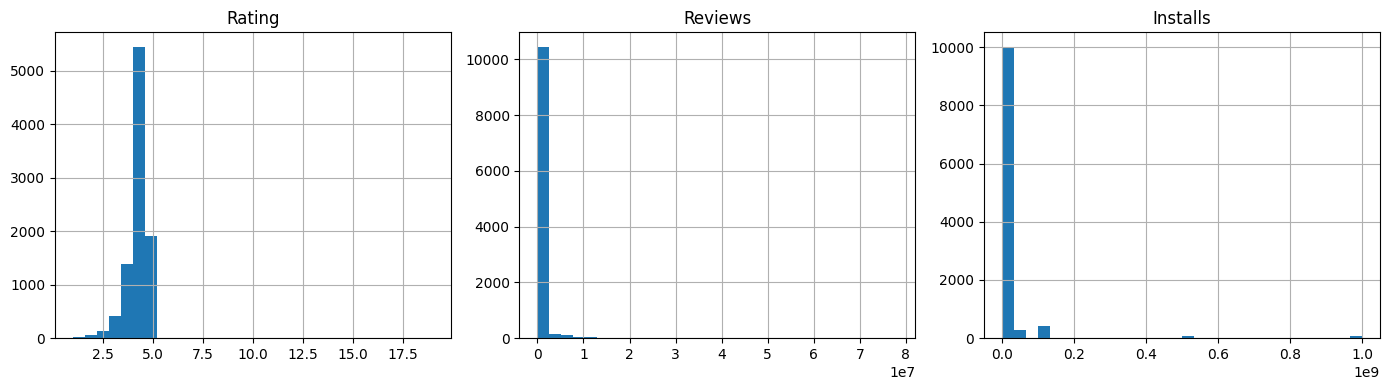

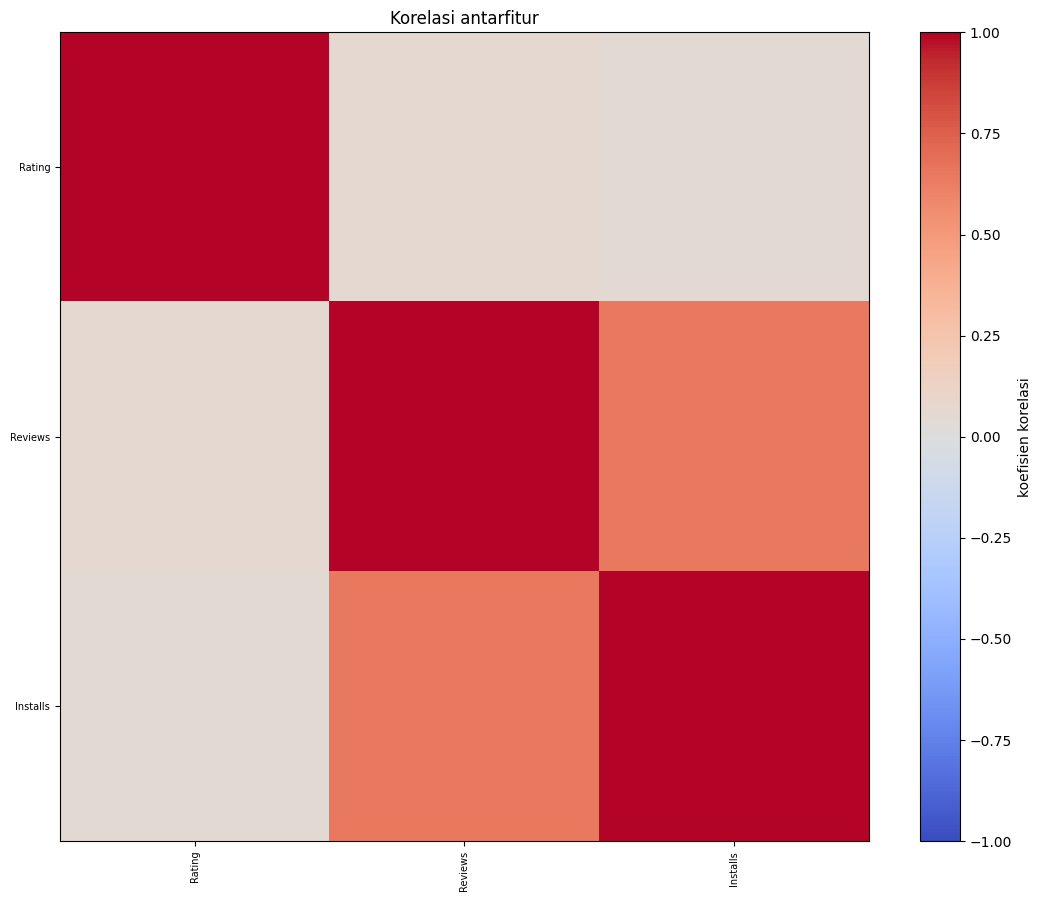

Pasangan berkorelasi di atas 0,9: tidak ada
Fitur kembar membuat satu dimensi dihitung dua kali oleh K-Means.
Bagian 4 menguji pengaruh membuang salah satunya.


In [33]:
num.hist(figsize=(14, 4), bins=30, layout=(1, num.shape[1]))
plt.tight_layout(); plt.savefig('gambar/eda_distribusi.png', dpi=110); plt.show()

kor = num.corr()
plt.figure(figsize=(11, 9))
plt.imshow(kor, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(label='koefisien korelasi')
plt.xticks(range(len(kor)), kor.columns, rotation=90, fontsize=7)
plt.yticks(range(len(kor)), kor.columns, fontsize=7)
plt.title('Korelasi antarfitur'); plt.tight_layout()
plt.savefig('gambar/eda_korelasi.png', dpi=110); plt.show()

kolom_num = num.columns.tolist()
tinggi = [(a, b, round(float(kor.loc[a, b]), 3))
          for i, a in enumerate(kolom_num) for b in kolom_num[i+1:]
          if abs(kor.loc[a, b]) > 0.9]
print('Pasangan berkorelasi di atas 0,9:', tinggi if tinggi else 'tidak ada')
print('Fitur kembar membuat satu dimensi dihitung dua kali oleh K-Means.')
print('Bagian 4 menguji pengaruh membuang salah satunya.')

## 1.6 Empat jawaban yang dinilai

**Tulis jawabannya di sel teks ini**, dengan klik dua kali pada sel. Keempatnya masuk ke laporan dan ditanyakan saat Progres 1. Jawaban harus Anda tulis sendiri dari keluaran sel 1.2b sampai 1.5; kode tidak dapat menghasilkannya.

1. **Satu baris data pada dataset ini mewakili apa?** _(jawab)_
2. Dua kolom dengan skala paling jauh berbeda, beserta min dan max-nya: _(jawab)_
3. Kolom mana yang dibuang karena berupa identitas, dan mengapa: _(jawab)_
4. Adakah fitur yang nilainya justru merupakan jawaban yang ingin dicari? Fitur seperti itu **tidak boleh** ikut membentuk klaster. _(jawab)_

> Petunjuk mencari jawabannya (bukan jawabannya):
> - **No. 1:** lihat keluaran akhir sel 1.3. Apakah nama aplikasi muncul lebih dari sekali? Bila iya, apa arti satu baris sebelum dan sesudah sel 1.7?
> - **No. 2:** ambil dari tabel min/mean/max di sel 1.4 (`Rating`, `Reviews`, `Installs` setelah 1.2b).
> - **No. 3:** lihat kolom non-numerik di sel 1.3 dan tanyakan apakah nilainya mengandung informasi perilaku aplikasi atau hanya penanda.
> - **No. 4:** periksa kolom yang tidak dipakai (`Category`, `Genres`, `Type`, `Content Rating`) dan `Installs`. Mana yang sudah berupa pengelompokan buatan pihak lain, dan mana yang hanya ukuran?


## 1.7 Membersihkan

Urutannya: buang duplikat identik, ubah tipe (1.2b), buang baris tidak sah, jadikan satu baris per aplikasi, pisahkan identitas, buang kolom non-numerik, imputasi median, lalu **batasi** pencilan dengan IQR.

Tiga langkah pertama adalah penyesuaian khusus Play Store. Langkah **satu baris per aplikasi** menjawab pertanyaan 1: bila satu nama aplikasi punya beberapa baris dengan nilai berbeda, yang dipertahankan adalah baris dengan `Reviews` terbanyak, karena itu rekaman yang paling lengkap. Bila kelompok memutuskan aturan lain, ubah sel ini **sebelum** `data_bersih.csv` dibagikan, dan sesuaikan pernyataan di 1.9.

Pencilan **dibatasi, bukan dibuang**. Pada data perilaku pelanggan, baris pencilan justru sering merupakan segmen yang ingin ditemukan — pelanggan bersaldo sangat besar, misalnya. Membuang barisnya sama dengan menghapus segmen itu sebelum K-Means melihatnya. Membatasi nilainya menahan pengaruh berlebih tanpa menghilangkan barisnya.

In [29]:
df = df_mentah.copy()

sebelum = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f'Duplikat identik dibuang: {sebelum - len(df)} baris')

# Ubah tipe: Reviews dan Installs dari teks menjadi angka (fungsi dari sel 1.2b)
df = ke_numerik(df)

# Buang baris tidak sah: baris bergeser (Reviews/Installs tidak terbaca) atau Rating di luar 1-5.
# Rating yang KOSONG tidak dibuang di sini; ia diimputasi median di bawah.
sah = ((df['Rating'].between(1, 5) | df['Rating'].isna())
       & df['Reviews'].notna() & df['Installs'].notna())
print(f'Baris tidak sah dibuang: {int((~sah).sum())} baris')
df = df[sah].reset_index(drop=True)

# Satu baris = satu aplikasi. Bila nama aplikasi berulang, pertahankan baris dengan Reviews terbanyak.
sebelum = len(df)
df = (df.sort_values('Reviews', ascending=False, kind='stable')
        .drop_duplicates(subset=ID_COL, keep='first')
        .sort_index().reset_index(drop=True))
print(f'Baris {ID_COL} berulang dijadikan satu: {sebelum - len(df)} baris dibuang')
print(f'Jumlah aplikasi (baris) sekarang: {len(df)}')

ids = None
if ID_COL in df.columns:
    ids = df[ID_COL].copy()
    df = df.drop(columns=[ID_COL])
    print(f'Kolom identitas {ID_COL} dipisahkan')

FITUR = ['Rating', 'Reviews', 'Installs']   # tiga fitur utama kelompok
bukan_angka = [c for c in df.columns if c not in FITUR]   # termasuk semua kolom teks
if bukan_angka:
    df = df.drop(columns=bukan_angka)
    print('Kolom non-numerik / di luar fitur dibuang:', bukan_angka)
    print('  (K-Means memakai fitur numerik saja, bukan one-hot seperti k-NN)')

kolom = df.columns.tolist()
print('Jumlah fitur:', len(kolom), kolom)

print('\nImputasi median:')
for c in kolom:
    n = int(df[c].isna().sum())
    if n:
        med = float(df[c].median())
        df[c] = df[c].fillna(med)
        print(f'  {c:<34} {n:>5} nilai -> median {med:,.2f}')

total = 0
persen = {}
print('\nPencilan dibatasi dengan IQR (bukan dibuang):')
for c in kolom:
    q1, q3 = df[c].quantile(0.25), df[c].quantile(0.75)
    iqr = q3 - q1
    bawah, atas = q1 - IQR_PENGALI*iqr, q3 + IQR_PENGALI*iqr
    kena = int(((df[c] < bawah) | (df[c] > atas)).sum())
    if kena:
        total += kena
        persen[c] = kena/len(df)*100
        df[c] = df[c].clip(bawah, atas)
        print(f'  {c:<34} {kena:>5} nilai ({persen[c]:5.2f}%)')
print('Total nilai dibatasi:', total)
berat = [c for c, p in persen.items() if p > 25]
if berat:
    print('\nPERHATIAN: lebih dari 25% nilai dibatasi pada', berat)
    print('Periksa apakah struktur klasternya masih ada. Putuskan sebagai kelompok')
    print('apakah IQR_PENGALI dinaikkan (sel bagian 0), SEBELUM data_bersih.csv dibagikan.')
print('Bila satu kolom lebih dari 25% nilainya dibatasi, periksa apakah')
print('struktur klasternya masih ada. Bila Silhouette anjlok, naikkan IQR_PENGALI.')


Duplikat identik dibuang: 483 baris
Baris tidak sah dibuang: 1 baris
Baris App berulang dijadikan satu: 698 baris dibuang
Jumlah aplikasi (baris) sekarang: 9659
Kolom identitas App dipisahkan
Kolom non-numerik / di luar fitur dibuang: ['Category', 'Size', 'Type', 'Price', 'Content Rating', 'Genres', 'Last Updated', 'Current Ver', 'Android Ver']
  (K-Means memakai fitur numerik saja, bukan one-hot seperti k-NN)
Jumlah fitur: 3 ['Rating', 'Reviews', 'Installs']

Imputasi median:
  Rating                              1463 nilai -> median 4.30

Pencilan dibatasi dengan IQR (bukan dibuang):
  Rating                               491 nilai ( 5.08%)
  Reviews                             1659 nilai (17.18%)
  Installs                            1981 nilai (20.51%)
Total nilai dibatasi: 4131
Bila satu kolom lebih dari 25% nilainya dibatasi, periksa apakah
struktur klasternya masih ada. Bila Silhouette anjlok, naikkan IQR_PENGALI.


## 1.8 Menyimpan dan membagikan data bersih

In [30]:
keluar = df.copy()
if ids is not None:
    keluar.insert(0, ID_COL, ids.to_numpy())
keluar.to_csv('data/data_bersih.csv', index=False)
print('Tersimpan: data/data_bersih.csv', keluar.shape)

from google.colab import files
files.download('data/data_bersih.csv')
files.download('gambar/eda_distribusi.png')
files.download('gambar/eda_korelasi.png')
print()
print('Langkah berikutnya:')
print('  1. Bagikan data_bersih.csv ke kedua anggota lain.')
print('  2. Commit data_bersih.csv ke folder data/ pada repositori kelompok.')
print('  3. Commit kedua gambar ke folder gambar/.')
print('  4. Unduh notebook ini: File -> Download -> Download .ipynb,')
print('     beri nama 01_penyiapan_data.ipynb, commit ke folder notebook/.')

Tersimpan: data/data_bersih.csv (9659, 4)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Langkah berikutnya:
  1. Bagikan data_bersih.csv ke kedua anggota lain.
  2. Commit data_bersih.csv ke folder data/ pada repositori kelompok.
  3. Commit kedua gambar ke folder gambar/.
  4. Unduh notebook ini: File -> Download -> Download .ipynb,
     beri nama 01_penyiapan_data.ipynb, commit ke folder notebook/.


## 1.9 Pernyataan urutan kerja

Ini salah satu luaran yang dinilai. Salin paragraf berikut ke `README.md`, **periksa kebenarannya terhadap yang benar-benar Anda jalankan**, lalu sesuaikan bila berbeda. Contoh yang HARUS dicocokkan: angka 1,5 harus sama dengan `IQR_PENGALI`; aturan "satu baris per aplikasi" harus sama dengan yang Anda jalankan di 1.7; dan bila Anda mengubah cara menangani `Rating` kosong, kalimatnya harus diubah.

> Pada cabang klastering tidak ada pemisahan data latih dan data uji, karena tidak ada label yang diuji. Pembersihan dilakukan sekali atas seluruh data Google Play Store: buang duplikat identik, ubah `Reviews` dan `Installs` dari teks menjadi angka, buang baris tidak sah (baris bergeser atau `Rating` di luar rentang 1-5), jadikan satu baris per aplikasi (nama aplikasi berulang dipertahankan pada baris dengan `Reviews` terbanyak), pisahkan kolom identitas `App`, buang kolom non-numerik, imputasi median, lalu pembatasan pencilan dengan IQR 1,5. Hasilnya disimpan sebagai `data_bersih.csv` (fitur `Rating`, `Reviews`, `Installs`) dan dipakai ketiga varian apa adanya. Penskalaan tidak dilakukan pada tahap pembersihan, melainkan di dalam tiap varian dan sekali lagi saat model final dilatih: `StandardScaler` di-fit satu kali pada data bersih, lalu disimpan sebagai `scaler.pkl` dan dipakai aplikasi web dengan `transform`, bukan `fit_transform`. Pengodean kategori tidak dipakai, karena pada K-Means hanya fitur numerik yang dipakai.

**Mengapa berbeda dari cabang klasifikasi.** Pada k-NN urutan wajibnya adalah bersihkan, pisahkan data, baru skalakan — penskalaan sebelum pemisahan membuat statistik data uji bocor ke pelatihan. Pada klastering tidak ada pemisahan, sehingga yang dijaga bukan kebocoran antar-himpunan, melainkan **kesamaan skala antara notebook dan aplikasi web**.

## Checklist Bagian 1

- [ ] `data/raw.csv` ada dan tidak pernah diubah lagi
- [ ] `data/data_bersih.csv` ada sebagai berkas di repositori, bukan hanya sel notebook
- [ ] `gambar/eda_distribusi.png` dan `gambar/eda_korelasi.png` ter-commit
- [ ] Empat jawaban di 1.6 sudah ditulis sendiri
- [ ] Pernyataan urutan kerja sudah masuk `README.md` dan sudah diperiksa
- [ ] Kedua anggota lain sudah menerima `data_bersih.csv`
- [ ] Mulai sekarang tidak ada lagi yang membersihkan data sendiri-sendiri